In [1]:
# Rucno importovanje ssp modula:
import sys
sys.path.insert(0, '/home/emir/Faks/SIS2/Knjiga_SIS2/Prilozi/SIS2_Kodovi/')
import ssp

# Importovanje ostalih biblioteka:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import hist

# Podesavanje prikaza za knjigu:
ssp.FORMATIRANJE_PRIKAZA = "BOOK"
ssp.REZOLUCIJA = "LOW"

# Podesavanje prikaza za rad studenata:
# ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
# ssp.REZOLUCIJA = "LOW"

In [2]:
#Programski kod 2.16

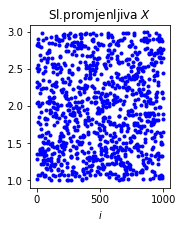

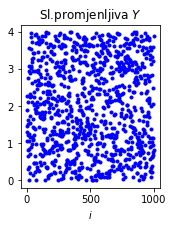

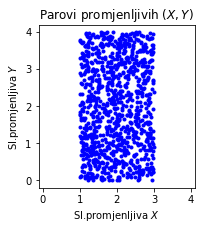

In [3]:
N = 1000

X = np.random.uniform(1, 3, N)
Y = np.random.uniform(0, 4, N)

ssp.slprom2D.realizacije(X,Y)

In [4]:
#Programski kod 2.17

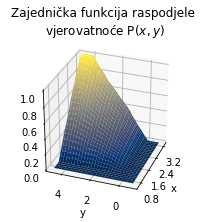

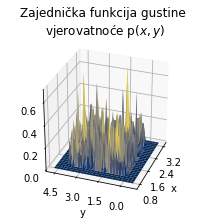

In [5]:
x, y, Pxy = ssp.slprom2D.PDF(X,Y, step = 0.1)

x_ , y_ , pxy = ssp.slprom2D.pdf(X,Y, step = 0.1)

In [6]:
#Programski kod 2.18

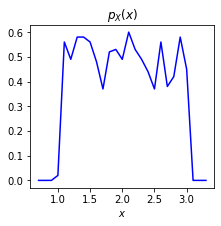

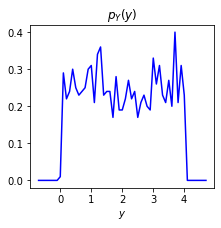

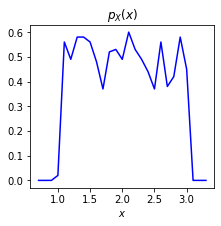

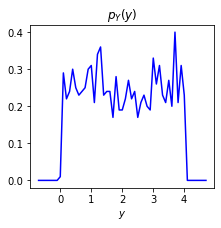

In [7]:
# Računanje marginalnih funkcija gustine vjerovatnoće iz parova (X,Y):
ssp.slprom2D.pdf_marg(X,Y);

# Računanje marginalnih funkcija gustine vjerovatnoće na osnovu p(x,y):
ssp.slprom2D.pdf_marg(x = x_ , y = y_ , p_xy = pxy);

In [8]:
#Programski kod 2.19

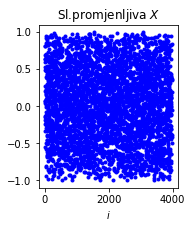

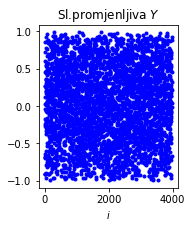

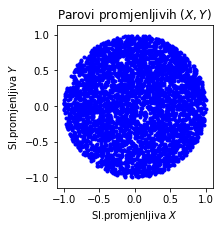

In [9]:
N = 5000
step = 0.1

X_init = np.random.uniform(-1, 1, N)
Y_init = np.random.uniform(-1, 1, N)

X = []; Y = [];

for i in range(N):
    if ((X_init[i])**2+(Y_init[i])**2<=1):
        X.append(X_init[i])
        Y.append(Y_init[i])     

X = np.array(X)
Y = np.array(Y)

ssp.slprom2D.realizacije(X,Y)

In [10]:
#Programski kod 2.20

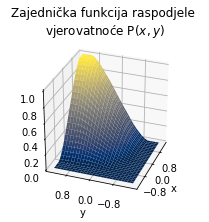

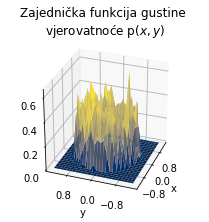

In [11]:
# Određivanje funkcije raspodjele vjerovatnoće:
x, y, Pxy = ssp.slprom2D.PDF(X, Y)

# Određivanje funkcije gustine vjerovatnoće:
x_, y_ , pxy = ssp.slprom2D.pdf(X, Y);

In [12]:
#Programski kod 2.21

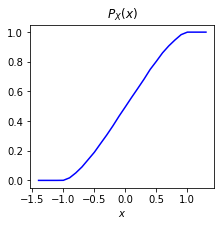

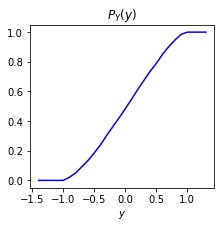

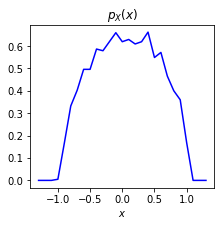

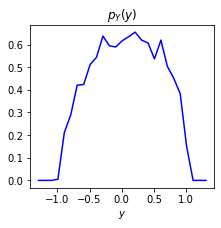

In [13]:
# Određivanje marginalne PDF iz zajedničke PDF
ssp.slprom2D.PDF_marg(x = x, y = y, P_xy = Pxy);

# Računanje marginalnih funkcija gustine vjerovatnoće na osnovu p(x,y):
ssp.slprom2D.pdf_marg(x = x_ , y = y_ , p_xy = pxy);

In [14]:
#Programski kod 2.22

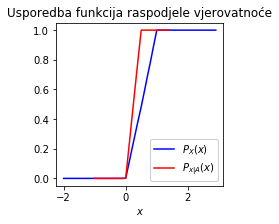

In [15]:
N = 5000 #Broj realizacija

X = np.random.uniform(0, 1, N) #Slucajna promjenjiva iz uniformne raspodjele
X_ako_A = []                    #Vektor za smjestanje slucajnih promjenjivih 
                               #iz uslovne vjerovatnoće

for i in range(len(X)):       #Glavna petlja
    if (X[i] < 0.5):
        X_ako_A.append(X[i])

X_ako_A = np.array(X_ako_A)     

# Proracun raspodjela vjerovatnoce
x, Px = ssp.slprom1D.PDF(X, 
                         prosirenje_opsega = 2.0,
                         prikaz = False)

x_ako_A, Px_ako_A = ssp.slprom1D.PDF(X_ako_A, 
                         prosirenje_opsega = 2.0,
                         prikaz = False)

# Usporedba raspodjela
ssp.slprom1D.grafik(x, Px, x_ako_A, Px_ako_A,
                    naslov = "Usporedba funkcija raspodjele vjerovatnoće",
                    legenda = ['$P_X(x)$', '$P_{x|A}(x)$'],
                    lokacija_lgd = 'lower right', x_labela = '$x$')


In [16]:
#Programski kod 2.23

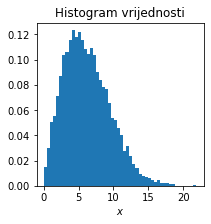

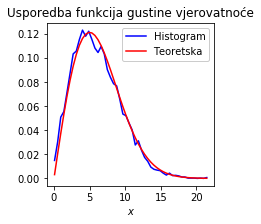

In [17]:
# PRISTUP 1 - koristenje histograma
N = 10000
broj_binova = 50

# Vektor od N realizacija slučajne promjenljive:
eta = 5; X = np.random.rayleigh(eta,N)

# Razvrstavanje realizacija u histograme
plt.figure(figsize=(3, 3))  
pdf_hist = hist(X, bins = broj_binova, density = True);
plt.title("Histogram vrijednosti"); plt.xlabel('$x$')

# Zatim se iz histograma izdvaja obvojnica 
pdf_x = []
for i in range(len(pdf_hist[2])):
    pdf_x.append(pdf_hist[2][i].get_height());
    
X_bin = pdf_hist[1][0:broj_binova];

def rayleigh(x):
    y = (x/eta**2)*np.exp(-0.5*(x/eta)**2)
    return y
    
ssp.slprom1D.grafik(X_bin, pdf_x, X_bin, rayleigh(X_bin),
                x_labela = '$x$', 
                naslov = "Usporedba funkcija gustine vjerovatnoće",
                legenda = ['Histogram','Teoretska'])

In [18]:
#Programski kod 2.24

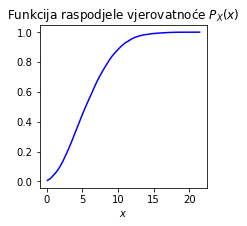

In [19]:
# PRISTUP 1 - korištenje histograma
Delta_X = X_bin[1]-X_bin[0]
PDF_X = Delta_X * np.cumsum(pdf_x)

ssp.slprom1D.grafik(X_bin, PDF_X,
                naslov = "Funkcija raspodjele vjerovatnoće $P_X(x)$",
                x_labela = "$x$")

In [20]:
#Programski kod 2.25

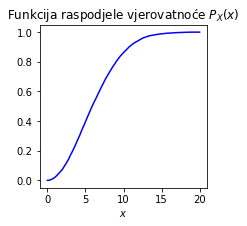

In [21]:
# PRISTUP 2 - korištenje definicionog izraza
step = 0.01; x_min = 0; x_max = 20
x = np.arange(x_min, x_max,step) 

P_x = np.zeros((len(x))) 

for i in range(len(x)):
    P_x[i] = sum (np.heaviside(x[i]-X, 1))/N

ssp.slprom1D.grafik(x, P_x,
                naslov = "Funkcija raspodjele vjerovatnoće $P_X(x)$",
                x_labela = "$x$")

In [22]:
#Programski kod 2.26

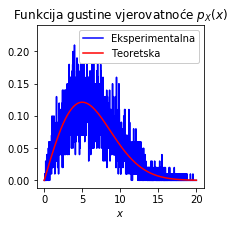

In [23]:
# PRISTUP 2 - korištenje definicionog izraza
pdf_x = np.diff(P_x)/step

ssp.slprom1D.grafik(x[1:], pdf_x, 
                 x, (x/(eta**2))*(np.exp(-x**2/(2*eta**2))),
                 naslov = "Funkcija gustine vjerovatnoće $p_X(x)$",
                 legenda = ['Eksperimentalna', 'Teoretska'],
                 x_labela = "$x$")

In [24]:
#Programski kod 2.27

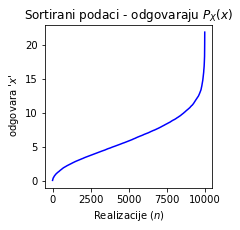

In [25]:
# PRISTUP 3 - koristenje sortiranja
sort_X = np.sort(X)
realizacije = np.arange(len(X))

ssp.slprom1D.grafik(realizacije, sort_X, 
                 naslov = "Sortirani podaci - odgovaraju $P_X(x)$",
                 x_labela = "Realizacije ($n$)",
                 y_labela = " odgovara '$x$'")

In [26]:
#Programski kod 2.28

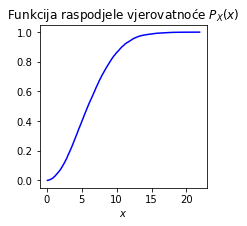

In [27]:
# PRISTUP 3 - koristenje sortiranja
from scipy import interpolate
f = interpolate.interp1d(sort_X, realizacije/len(X))

step = 0.01; x_min = min(X); x_max = max(X)
x = np.arange(x_min, x_max,step) 

P_x = f(x)   # interpolacija u novom vektoru

ssp.slprom1D.grafik(x, P_x,
                naslov = "Funkcija raspodjele vjerovatnoće $P_X(x)$",
                x_labela = "$x$")

In [28]:
#Programski kod 2.29

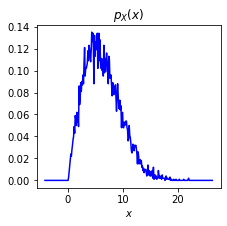

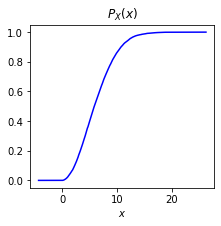

In [29]:
x, px = ssp.slprom1D.pdf(X)

x, Px = ssp.slprom1D.PDF(X)

In [30]:
#Programski kod 2.30 

In [31]:
# definiranje funkcije dvije promjenljive
def F(x, y):
    return np.sin(np.sqrt(x ** 2 + y ** 2))     

In [32]:
#Programski kod 2.31

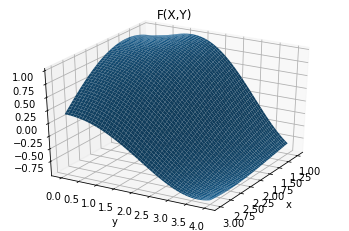

In [33]:
# Priprema x-y vrijednosti za crtanje:
step = 0.01; xmin = 1; xmax =3; ymin = 0; ymax = 4;
x = np.arange(xmin, xmax, step)
y = np.arange(ymin, ymax, step)
X, Y = np.meshgrid(x, y)

# Računa se željena funkcija:
p = F(X, Y) 

# Prikaz:        
plt.figure()

ax = plt.axes(projection='3d');
ax.view_init(elev=30, azim=30)
ax.set_xlabel("x"); 
ax.set_ylabel("y"); 
ax.set_title("F(X,Y)");
ax.plot_surface(X, Y, p);

plt.show()    

In [34]:
#Programski kod 2.32

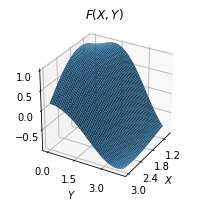

In [35]:
ssp.slprom2D.grafik(X,Y,p,
                elevacija = 30, azimut = 30)

In [36]:
#Programski kod 2.33 

In [37]:
# Zajednička funkcija raspodjele vjerovatnoće
def PDF(X, Y):    
    # ...
    # ...
    
    raspon_x = np.max(X) - np.min(X)
    raspon_y = np.max(Y) - np.min(Y)
    
    x = np.arange(np.min(X)-prosirenje_opsega*raspon_x ,
                  np.max(X)+prosirenje_opsega*raspon_x ,step)
    y = np.arange(np.min(Y)-prosirenje_opsega*raspon_y, 
                  np.max(Y)+prosirenje_opsega*raspon_y,step)
    
    Xm, Ym = np.meshgrid(x, y)
    P = np.zeros((len(x),len(y)))

    N = len(X)

    #Formiranje funkcije raspodjele vjerovatnoće
    for i in range(len(x)):
        for j in range(len(y)):        
            P[i,j]= sum(np.heaviside(x[i]-X,1) * np.heaviside(y[j]-Y,1))/N  
    
    # ...
    # ...    
    return x, y, P


# Zajednička funkcija gustine vjerovatnoće
def pdf(X, Y):     
    # ...
    # ...      
    
    p = np.diff(np.diff(P,1, axis = 0)/step,1, axis = 1)/step
    x = x[1:]
    y = y[1:]    
         
    # ...
    # ...
    return x, y, p    

In [38]:
#Programski kod 2.34 

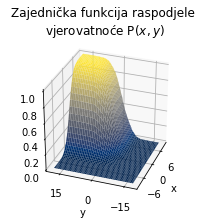

In [39]:
N = 1000

X = np.random.normal(0, 2, N)
Y = np.random.normal(0, 4, N)

# Određivanje funkcije raspodjele vjerovatnoće:
x, y, P_xy = ssp.slprom2D.PDF(X,Y)

In [40]:
#Programski kod 2.35 

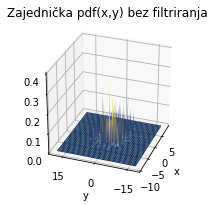

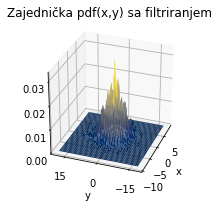

In [41]:
# Određivanje funkcije gustine vjerovatnoće:
x_ , y_ , p_xy = ssp.slprom2D.pdf(X,Y,
                                 naslov = "Zajednička pdf(x,y) bez filtriranja");

x_ , y_ , p_xy = ssp.slprom2D.pdf(X,Y,
                                  koef_filtriranja = 3.0,
                                  naslov = "Zajednička pdf(x,y) sa filtriranjem");

In [42]:
#Programski kod 2.36

In [43]:
def pdf_marg(X = None, Y = None, p_xy = None):
    # ...
    # ...   
        px = np.sum(p_xy, axis=1)*step
        py = np.sum(p_xy, axis=0)*step
    # ...
    # ...  


def PDF_marg(X = None, Y = None, step = 0.1, prosirenje_opsega = .2,
             x = None, y = None, P_xy = None, 
            prikaz = True,                         
            promjenljiva1 = 'X', promjenljiva2 = 'Y',
            naslov = None):    
    # ...
    # ... 
                 
        Px = P_xy[:,-1]
        Py = P_xy[-1,:]
        
    # ...
    # ...    

In [44]:
#Programski kod 2.37

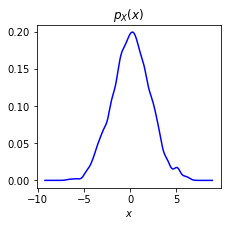

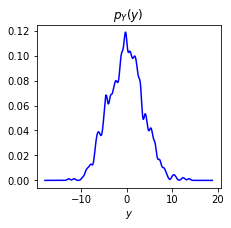

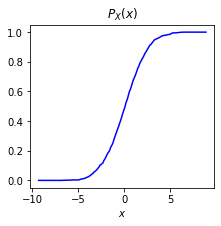

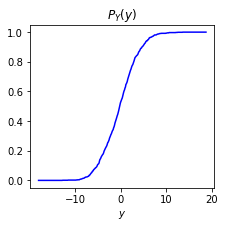

In [45]:
ssp.slprom2D.pdf_marg(x = x_, y = y_, p_xy = p_xy);
ssp.slprom2D.PDF_marg(x = x, y = y, P_xy = P_xy);